<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/05_Grocery_Subcategory_Disaggregation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# 1. Load the uploaded datasets
fuel_df = pd.read_csv('cleaned_fuel_grocery_data.csv')
sub_df = pd.read_csv('cleaned_grocery_subcategories.csv')

# 2. Print the column names of both datasets to understand their structure
print("=== Columns in Fuel Dataset ===")
print(fuel_df.columns.tolist())

print("\n=== Columns in Grocery Subcategories Dataset ===")
print(sub_df.columns.tolist())

# 3. Attempt to find the column containing the category names and print its unique values
category_columns = [col for col in sub_df.columns if 'cat' in col.lower() or 'item' in col.lower()]

if category_columns:
    target_col = category_columns[0]
    print(f"\n=== Unique values in the '{target_col}' column ===")
    print(sub_df[target_col].unique().tolist())
else:
    print("\nCould not automatically find the category column. Here are the first 5 rows to check manually:")
    print(sub_df.head())

=== Columns in Fuel Dataset ===
['Month', 'Diesel', 'Food and non-alcoholic beverages', 'Petrol', 'Month_DT', 'Month_Diff']

=== Columns in Grocery Subcategories Dataset ===
['Date', 'Item', 'Price']

=== Unique values in the 'Item' column ===
['Bread, white sliced pan, large (800g)', 'Brown, wholemeal flour per 2 kg', 'Butter per lb', 'Full fat milk per 2 litre', 'Jam per lb', 'Large eggs per half dozen', 'Marmalade per lb', 'Sirloin steak per kg', 'Spaghetti per 500g', 'Tea bags per 80', 'Tomatoes per kg', 'Uncooked chicken medium size 1.6kg', 'White granulated sugar per 1 kg', 'White, self raising flour per 2 kg']


In [ ]:
import pandas as pd
import numpy as np

# 1. Load datasets
fuel_df = pd.read_csv('cleaned_fuel_grocery_data.csv')
sub_df = pd.read_csv('cleaned_grocery_subcategories.csv')

# 2. Standardize date columns for merging
# Convert 'Month_DT' in fuel dataset to datetime objects
fuel_df['Month_DT'] = pd.to_datetime(fuel_df['Month_DT'])

# Rename 'Date' to 'Month_DT' in subcategory dataset to match, then convert to datetime
sub_df.rename(columns={'Date': 'Month_DT'}, inplace=True)
sub_df['Month_DT'] = pd.to_datetime(sub_df['Month_DT'])

# 3. Define categorization lists based on the unique items found
perishables = [
    'Butter per lb',
    'Full fat milk per 2 litre',
    'Large eggs per half dozen',
    'Sirloin steak per kg',
    'Tomatoes per kg',
    'Uncooked chicken medium size 1.6kg'
]

# Function to assign categories
def assign_group(item):
    if item in perishables:
        return 'Perishable/High-Transport'
    else:
        # All other items on our list fall into the Shelf-Stable category
        return 'Shelf-Stable'

# Apply categorization to a new 'Group' column
sub_df['Group'] = sub_df['Item'].apply(assign_group)

# 4. Pivot the data
# Calculate the average price for each group per month
pivot_df = sub_df.pivot_table(
    index='Month_DT',
    columns='Group',
    values='Price',
    aggfunc='mean' # Taking the mean price of the items in each group
).reset_index()

# 5. Merge with fuel data
# Use an inner join to keep only the months where both fuel and grocery data exist
merged_df = pd.merge(fuel_df, pivot_df, on='Month_DT', how='inner')

# Print the result to verify
print("=== Merged Dataset Preview ===")
print(merged_df[['Month_DT', 'Diesel', 'Petrol', 'Perishable/High-Transport', 'Shelf-Stable']].head())

=== Merged Dataset Preview ===
    Month_DT  Diesel  Petrol  Perishable/High-Transport  Shelf-Stable
0 2016-01-01    65.0    72.8                   5.080333      1.885250
1 2016-02-01    61.1    70.5                   4.989000      1.898625
2 2016-03-01    61.9    70.0                   4.839167      1.903375
3 2016-04-01    64.2    73.1                   4.963833      1.897000
4 2016-05-01    65.3    74.7                   5.032000      1.886750


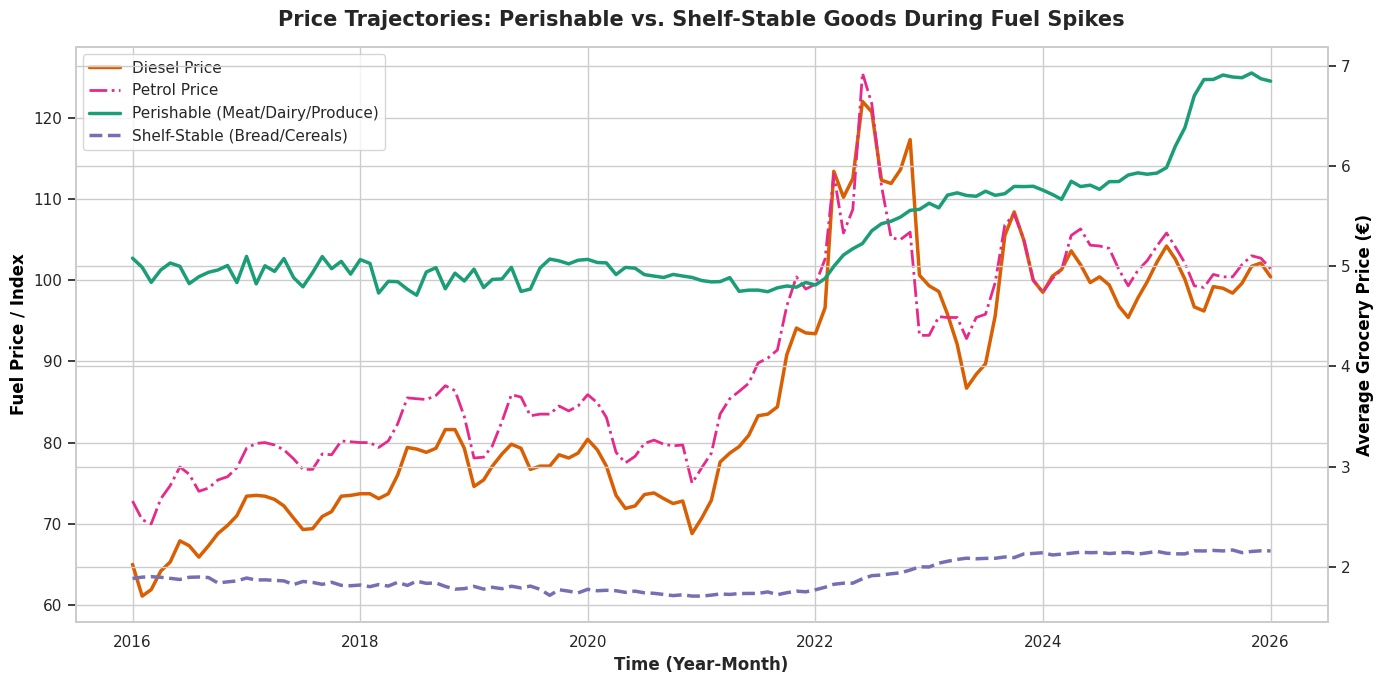

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set visualization style
sns.set_theme(style="whitegrid")

# 2. Create a figure and primary axis
fig, ax1 = plt.subplots(figsize=(14, 7))

# 3. Plot Fuel Prices on the primary Y-axis (Left)
color_diesel = '#d95f02' # Orange
color_petrol = '#e7298a' # Pink
ax1.plot(merged_df['Month_DT'], merged_df['Diesel'], color=color_diesel, linewidth=2.5, label='Diesel Price')
ax1.plot(merged_df['Month_DT'], merged_df['Petrol'], color=color_petrol, linewidth=2, linestyle='-.', label='Petrol Price')

ax1.set_xlabel('Time (Year-Month)', fontweight='bold', fontsize=12)
ax1.set_ylabel('Fuel Price / Index', color='black', fontweight='bold', fontsize=12)
ax1.tick_params(axis='y')

# 4. Create a secondary Y-axis (Right) for Grocery Prices
ax2 = ax1.twinx()
color_perish = '#1b9e77' # Green
color_shelf = '#7570b3'  # Purple

ax2.plot(merged_df['Month_DT'], merged_df['Perishable/High-Transport'], color=color_perish, linewidth=2.5, label='Perishable (Meat/Dairy/Produce)')
ax2.plot(merged_df['Month_DT'], merged_df['Shelf-Stable'], color=color_shelf, linewidth=2.5, linestyle='--', label='Shelf-Stable (Bread/Cereals)')

ax2.set_ylabel('Average Grocery Price (€)', color='black', fontweight='bold', fontsize=12)
ax2.tick_params(axis='y')

# 5. Add Title
plt.title('Price Trajectories: Perishable vs. Shelf-Stable Goods During Fuel Spikes', fontsize=15, fontweight='bold', pad=15)

# 6. Combine legends from both axes into one box
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True, facecolor='white')

# 7. Render the plot
plt.tight_layout()
plt.show()